# Discovery Engine: how a relevance ranker becomes an explorer

This notebook is about **Stage 4, the discovery re-ranking engine**. Retrieval, filtering and the XGBoost ranker are already trained
(`scripts/train_and_simulate.py`) and are only loaded here.

| Part | Question |
|---|---|
| 1 | Why is a discovery engine needed? (cold-start bottleneck, short) |
| 2 | What exactly happens to one request, step by step? (utility, guardrails, LinUCB, MMR, propensity) |
| 3 | How does the exploration bonus behave, and what does it do to cold-start items? |
| 4 | What do the knobs alpha (exploration) and lambda (diversity) trade away? (exact, noise-free frontier) |
| 5 | Do the guardrails throw away good items? |
| 6 | How do the four policies compare on **discovery metrics**? |
| 7 | Online learning demo: one feedback event updates the bandit |
| 8 | Can we evaluate discovery policies offline? (IPS / SNIPS / DR vs ground truth) |

In [1]:
import sys, json, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

from src.utils import load_config, gpu_info
from src.system import load_system
from src.data.state import TIER_NAMES
from src.data.synthetic_retail import SimEnvironment
from src.reranker.diversity_mmr import mmr_select, similarity_matrix, minmax
from src.reranker.bandit import LinUCBBandit
from src.evaluation import metrics as M
from src.evaluation.ope import run_ope, ope_table
from src.simulation import _clone_bandit

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
POL = ["pure_ranker", "epsilon_greedy", "linucb_mmr", "linucb_high_expl"]
LAB = {"pure_ranker": "Pure ranker", "epsilon_greedy": "Epsilon-greedy", "linucb_mmr": "LinUCB + MMR", "linucb_high_expl": "High-explore LinUCB"}
COL = {"pure_ranker": "#6B7A8F", "epsilon_greedy": "#F4A259", "linucb_mmr": "#2A9D8F", "linucb_high_expl": "#E4572E"}
MET = ROOT / "output" / "metrics"

cfg = load_config()
S = load_system(cfg)                 # loads world, two-tower, XGBoost, trained LinUCB state
pipe, world = S["pipeline"], S["world"]
env = SimEnvironment(world, seed=0)  # hidden ground truth: only used to *evaluate*, never by the models
print("device:", gpu_info()["device"], "| items:", world.n_items, "| users:", world.n_users,
      "| cold-start items:", int(world.items.is_cold.sum()))
print("bandit updates already absorbed:", {k: b.n_updates for k, b in pipe.bandits.items()})

device: NVIDIA GeForce RTX 3090 | items: 10000 | users: 2000 | cold-start items: 1500
bandit updates already absorbed: {'linucb_mmr': 35000, 'linucb_high_expl': 35000}


## 1. Why discovery? The cold-start bottleneck

History features are empty for new SKUs, so the ranker scores them lower **even when they are exactly as relevant**.
Below: ranker score vs. ground-truth relevance, split by true-relevance quintile (data from the training run).

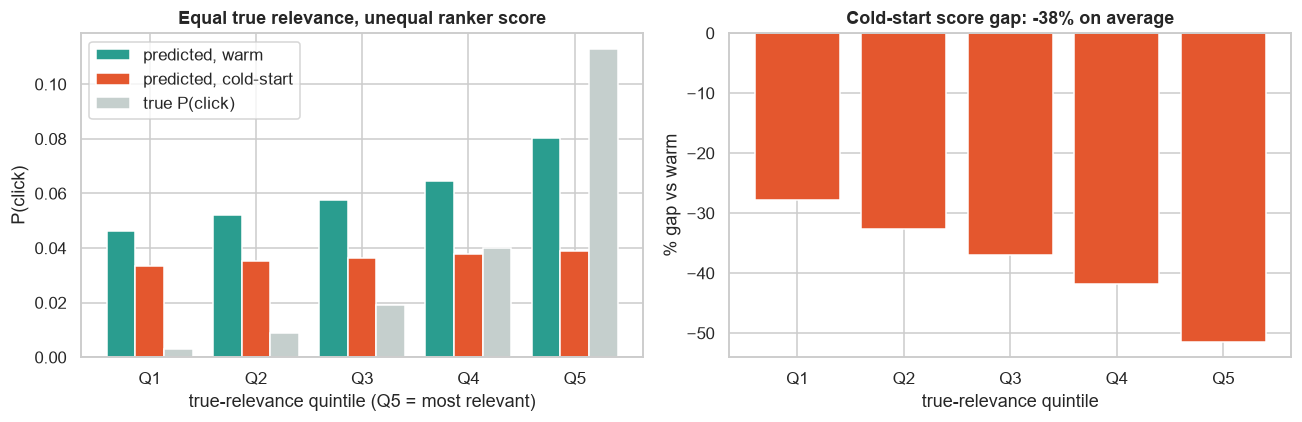

mean predicted P(click): cold=0.036 vs warm=0.065; P(buy) over-prediction for cold items: 2.6x


In [2]:
gap = json.load(open(MET / "cold_start_bottleneck.json"))
b = pd.DataFrame(gap["matched_relevance_bins"])
x = np.arange(len(b)); w = 0.27
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(x - w, b.pred_warm, w, label="predicted, warm", color="#2A9D8F")
ax[0].bar(x, b.pred_cold, w, label="predicted, cold-start", color="#E4572E")
ax[0].bar(x + w, b.true_cold, w, label="true P(click)", color="#C5CFCD")
ax[0].set(title="Equal true relevance, unequal ranker score", xlabel="true-relevance quintile (Q5 = most relevant)", ylabel="P(click)",
          xticks=x, xticklabels=[f"Q{i+1}" for i in x]); ax[0].legend()
ax[1].bar(x, 100 * b.rel_gap, color="#E4572E")
ax[1].set(title=f"Cold-start score gap: {100*gap['mean_relative_gap_matched']:.0f}% on average", xlabel="true-relevance quintile", ylabel="% gap vs warm", xticks=x, xticklabels=[f"Q{i+1}" for i in x])
plt.tight_layout(); plt.show()
print(f"mean predicted P(click): cold={gap['mean_pred_click_cold']:.3f} vs warm={gap['mean_pred_click_warm']:.3f}; "
      f"P(buy) over-prediction for cold items: {gap['calibration_ratio_buy_cold']:.1f}x")

## 2. One request through the discovery engine

We follow **user 7** (a gourmet-persona shopper) through the five steps. `pipe.prepare()` runs stages 1-3 plus the candidate-level
parts of stage 4 (utility, guardrail pre-filter, context vectors).

In [3]:
UID = 7
user = world.users.iloc[UID]
print(f"user {UID}: persona={user.persona_name}, avg item price={user.avg_item_price:.2f}, buys in 90d={user.n_buys_90d}")
pack = pipe.prepare(UID, day=90); pipe.timer.commit()

fc, gc = pack.stage_counts["filter"], pack.stage_counts["guardrails"]
funnel = pd.DataFrame({"stage": ["retrieved (two-tower top-200)", "after stock + 14-day purchase filter", "after guardrails", "slate"],
                       "items": [fc["retrieved"], fc["kept"], gc["n_out"], 5]})
display(funnel)
print(f"guardrails dropped: {gc['dropped_price_band']} by the price band, {gc['dropped_fatigue']} by impression fatigue")

user 7: persona=gourmet_specialty, avg item price=3.61, buys in 90d=3


,stage,items
0,retrieved (two-tower top-200),200
1,after stock + 14-day purchase filter,192
2,after guardrails,65
3,slate,5


guardrails dropped: 127 by the price band, 0 by impression fatigue


### Step 1: multi-objective utility with a novelty term
`U = w1*p(click) + w2*p(buy)*margin + w3*novelty`. Novelty is computed from the user's live history: unseen subcategory 1.0, unseen brand 0.5, new SKU 0.25, previously bought 0.

65 candidates survive; tier mix:


,n
tier,
unseen_subcategory,31
new_sku,17
unseen_brand,15
previously_bought,2


,item,subcat,price,cold_start,tier,novelty,p_click,p_buy,margin,U_relevance_only,U_with_novelty,true_reward
1,6241,8,1.34,False,new_sku,0.25,0.345,0.066,0.280,0.382,0.392,0.245
3,9592,8,1.69,False,previously_bought,0.00,0.345,0.066,0.118,0.360,0.360,0.257
12,1236,8,1.74,False,new_sku,0.25,0.230,0.066,0.194,0.255,0.265,0.147
0,8823,54,1.26,False,previously_bought,0.00,0.230,0.066,0.168,0.252,0.252,0.210
64,1020,8,2.83,False,unseen_brand,0.50,0.147,0.066,0.276,0.183,0.203,0.025
2,9872,25,3.82,False,unseen_subcategory,1.00,0.147,0.030,0.135,0.155,0.195,0.161
18,659,8,4.24,False,unseen_brand,0.50,0.147,0.041,0.266,0.169,0.189,0.136
14,3830,35,6.31,False,new_sku,0.25,0.147,0.030,0.317,0.166,0.176,0.091


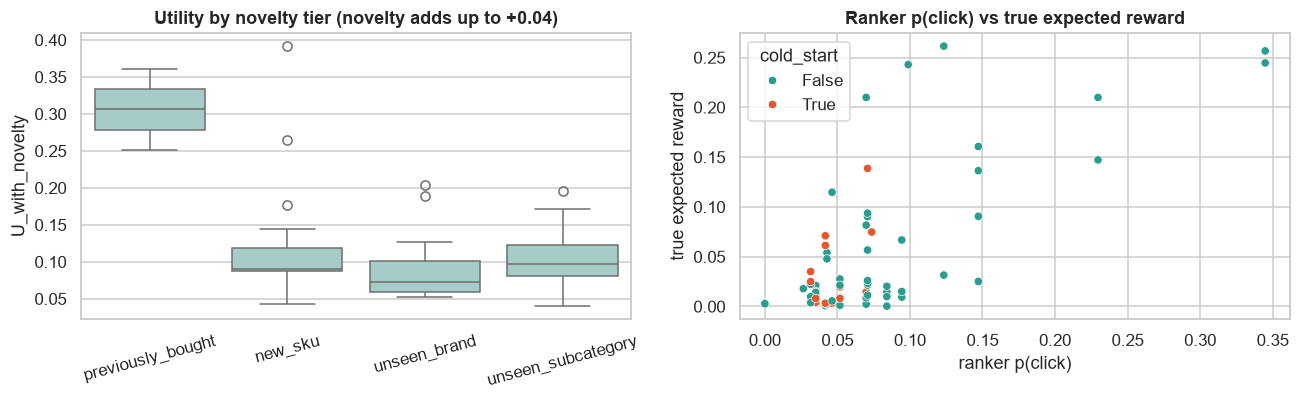

In [4]:
cand = pd.DataFrame({
    "item": pack.items, "subcat": pack.subcat, "price": pack.price, "cold_start": pack.is_cold,
    "tier": [TIER_NAMES[t] for t in pack.tier], "novelty": pack.novelty, "p_click": pack.pc, "p_buy": pack.pb,
    "margin": pack.margin, "U_relevance_only": pack.u_rel.cpu().numpy(), "U_with_novelty": pack.u_full.cpu().numpy(),
})
cand["true_reward"] = env.expected_reward(np.full(len(cand), UID), pack.items, pack.unseen_sub)   # ground truth, evaluation only
print(f"{len(cand)} candidates survive; tier mix:"); display(cand.tier.value_counts().to_frame("n"))
display(cand.sort_values("U_with_novelty", ascending=False).head(8).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
order = ["previously_bought", "new_sku", "unseen_brand", "unseen_subcategory"]
sns.boxplot(data=cand, x="tier", y="U_with_novelty", order=order, ax=ax[0], color="#9ED3CC")
ax[0].set(title="Utility by novelty tier (novelty adds up to +0.04)", xlabel=""); ax[0].tick_params(axis="x", rotation=15)
sns.scatterplot(data=cand, x="p_click", y="true_reward", hue="cold_start", palette={False: "#2A9D8F", True: "#E4572E"}, ax=ax[1], s=30)
ax[1].set(title="Ranker p(click) vs true expected reward", xlabel="ranker p(click)", ylabel="true expected reward")
plt.tight_layout(); plt.show()

### Step 2: hard guardrails
Fatigue (more than 3 unclicked impressions in 7 days) and the price band for *explored* items (cold-start or unseen, within +-30% of the user's average price) are applied before scoring; the subcategory cap (max 2) is enforced inside MMR. Section 5 examines what the price band costs.

### Step 3: LinUCB exploration bonus
`Score_bandit = U + alpha * sqrt(x' A^-1 x)`, one disjoint model per category plus shared hybrid parameters.

mean bonus  cold-start: 0.0610   warm: 0.0321


,item,tier,cold_start,U_with_novelty,bonus,bandit_score,rank_by_U,rank_by_score,rank_shift
24,155,new_sku,True,0.064,0.069,0.133,56,37,19
17,9092,unseen_brand,True,0.053,0.068,0.121,62,43,19
31,4928,unseen_brand,True,0.075,0.068,0.143,50,31,19
28,136,unseen_brand,True,0.080,0.068,0.148,43,25,18
25,6551,unseen_brand,True,0.059,0.069,0.128,59,41,18
53,3656,unseen_subcategory,True,0.092,0.066,0.159,31,16,15


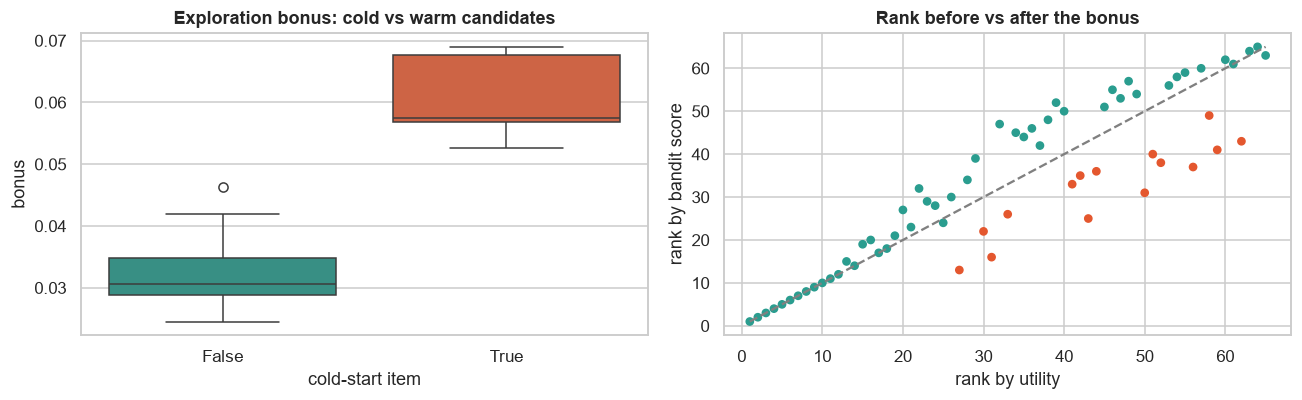

In [5]:
pol = pipe.policies["linucb_mmr"]
sc = pipe.score(pack, pol)
cand["bonus"] = sc["bonus"].cpu().numpy(); cand["bandit_score"] = sc["score"].cpu().numpy()
cand["rank_by_U"] = cand.U_with_novelty.rank(ascending=False).astype(int)
cand["rank_by_score"] = cand.bandit_score.rank(ascending=False).astype(int)
cand["rank_shift"] = cand.rank_by_U - cand.rank_by_score
print("mean bonus  cold-start: %.4f   warm: %.4f" % (cand[cand.cold_start].bonus.mean(), cand[~cand.cold_start].bonus.mean()))
display(cand.sort_values("rank_shift", ascending=False).head(6)[["item", "tier", "cold_start", "U_with_novelty", "bonus", "bandit_score", "rank_by_U", "rank_by_score", "rank_shift"]].round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=cand, x="cold_start", y="bonus", ax=ax[0], palette=["#2A9D8F", "#E4572E"]); ax[0].set(title="Exploration bonus: cold vs warm candidates", xlabel="cold-start item")
ax[1].scatter(cand.rank_by_U, cand.rank_by_score, c=np.where(cand.cold_start, "#E4572E", "#2A9D8F"), s=22)
ax[1].plot([1, len(cand)], [1, len(cand)], "--", color="grey"); ax[1].set(title="Rank before vs after the bonus", xlabel="rank by utility", ylabel="rank by bandit score")
plt.tight_layout(); plt.show()

### Step 4: MMR slate assembly, traced step by step
`next = argmax [ lambda*Score - (1-lambda)*max_j Sim(i,j) ]`, with `Sim = 0.6*embedding cosine + 0.4*same-subcategory`.

In [6]:
lam, K, cap = pol.lam, 5, cfg["guardrails"]["max_per_subcategory"]
s_norm = minmax(sc["score"]).cpu().numpy()
sim = similarity_matrix(pack.emb, pack.subcat_t, cfg["mmr"]["w_embed_sim"], cfg["mmr"]["w_subcat_sim"]).cpu().numpy()
chosen, trace, max_sim, cnt = [], [], np.zeros(len(s_norm)), {}
for step in range(K):
    val = lam * s_norm - (1 - lam) * max_sim
    val[chosen] = -1e9
    for sub, c in cnt.items():
        if c >= cap: val[pack.subcat == sub] -= 1e6
    j = int(val.argmax())
    trace.append({"slot": step + 1, "item": int(pack.items[j]), "tier": TIER_NAMES[pack.tier[j]], "cold": bool(pack.is_cold[j]),
                  "norm_score": s_norm[j], "lambda*score": lam * s_norm[j], "mmr_penalty": (1 - lam) * max_sim[j], "objective": val[j],
                  "rank_by_score_alone": int((s_norm > s_norm[j]).sum()) + 1})
    chosen.append(j); cnt[pack.subcat[j]] = cnt.get(pack.subcat[j], 0) + 1; max_sim = np.maximum(max_sim, sim[j])
trace = pd.DataFrame(trace); display(trace.round(3))
picks, pens, _ = mmr_select(sc["score"], pack.emb, pack.subcat_t, K, lam, cfg["mmr"]["w_embed_sim"], cfg["mmr"]["w_subcat_sim"], cap)
assert picks == chosen, "trace must match the library implementation"
print("trace matches src.reranker.diversity_mmr.mmr_select:", picks == chosen)

,slot,item,tier,cold,norm_score,lambda*score,mmr_penalty,objective,rank_by_score_alone
0,1,6241,new_sku,False,1.000,0.750,0.000,0.750,1
1,2,9592,previously_bought,False,0.936,0.702,0.168,0.535,2
2,3,8823,previously_bought,False,0.579,0.435,0.063,0.372,4
3,4,9872,unseen_subcategory,False,0.431,0.323,0.063,0.261,6
4,5,1424,unseen_subcategory,False,0.373,0.280,0.037,0.243,9


trace matches src.reranker.diversity_mmr.mmr_select: True


### Step 5: Boltzmann propensities
`P(i|u) = softmax(Score/tau)` over the guard-railed pool. These are what get logged next to every displayed item.

sum of propensities: 1.0 | tau = 0.06


,slot,item,tier,cold_start,U_with_novelty,bonus,bandit_score,propensity,mmr_penalty
1,1,6241,new_sku,False,0.3917,0.0383,0.4300,0.4120,0.0000
3,2,9592,previously_bought,False,0.3604,0.0464,0.4068,0.2798,0.1675
0,3,8823,previously_bought,False,0.2517,0.0254,0.2771,0.0322,0.0629
2,4,9872,unseen_subcategory,False,0.1953,0.0278,0.2231,0.0131,0.0625
44,5,1424,unseen_subcategory,False,0.1719,0.0303,0.2022,0.0093,0.0366


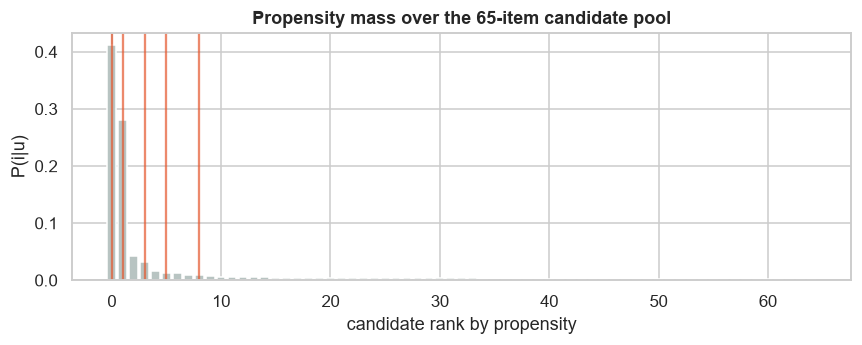

In [7]:
probs = pipe.policy_probs(sc["score"], pol).cpu().numpy()
cand["propensity"] = probs
print("sum of propensities:", probs.sum().round(6), "| tau =", pol.tau)
slot_tab = cand.iloc[chosen][["item", "tier", "cold_start", "U_with_novelty", "bonus", "bandit_score", "propensity"]].copy()
slot_tab.insert(0, "slot", range(1, K + 1)); slot_tab["mmr_penalty"] = trace.mmr_penalty.values
display(slot_tab.round(4))
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(range(len(probs)), np.sort(probs)[::-1], color="#B8C4C2"); ax.set(title="Propensity mass over the %d-item candidate pool" % len(probs), xlabel="candidate rank by propensity", ylabel="P(i|u)")
for j in chosen: ax.axvline(int((probs > probs[j]).sum()), color="#E4572E", alpha=.7)
plt.tight_layout(); plt.show()

### The same request under all four policies

In [8]:
rows = []
for p in POL:
    out = pipe.recommend(UID, p, day=90)
    for s in out["slate"]:
        rows.append({"policy": LAB[p], "slot": s["slot"] + 1, "item": s["item_id"], "tier": s["novelty_tier"], "cold": s["is_cold_start"],
                     "p_click": s["p_click"], "base_utility": s["base_utility"], "bonus": s["exploration_bonus"],
                     "mmr_penalty": s["mmr_penalty"], "propensity": s["propensity_score"], "ILD": out["ild"]})
cmp_tab = pd.DataFrame(rows)
display(cmp_tab.round(3).style.apply(lambda r: ["background-color:#FBE3DB" if r.cold else "" for _ in r], axis=1))
print(cmp_tab.groupby("policy", sort=False).agg(cold=("cold", "sum"), unseen_tier=("tier", lambda t: int(t.isin(["unseen_brand", "unseen_subcategory"]).sum())), ILD=("ILD", "first")).round(3))

,policy,slot,item,tier,cold,p_click,base_utility,bonus,mmr_penalty,propensity,ILD
0,Pure ranker,1,6241,new_sku,False,0.345000,0.382000,0.000000,0.000000,0.421000,0.706000
1,Pure ranker,2,9592,previously_bought,False,0.345000,0.360000,0.000000,0.000000,0.295000,0.706000
2,Pure ranker,3,8823,previously_bought,False,0.230000,0.252000,0.000000,0.000000,0.048000,0.706000
3,Pure ranker,4,3830,new_sku,False,0.147000,0.166000,0.000000,0.000000,0.012000,0.706000
4,Pure ranker,5,9872,unseen_subcategory,False,0.147000,0.155000,0.000000,0.000000,0.010000,0.706000
5,Epsilon-greedy,1,6241,new_sku,False,0.345000,0.382000,0.000000,0.000000,0.360000,0.784000
6,Epsilon-greedy,2,9592,previously_bought,False,0.345000,0.360000,0.000000,0.000000,0.253000,0.784000
7,Epsilon-greedy,3,9435,unseen_subcategory,True,0.035000,0.044000,0.000000,0.000000,0.004000,0.784000
8,Epsilon-greedy,4,3830,new_sku,False,0.147000,0.166000,0.000000,0.000000,0.012000,0.784000
9,Epsilon-greedy,5,9872,unseen_subcategory,False,0.147000,0.155000,0.000000,0.000000,0.011000,0.784000


                     cold  unseen_tier    ILD
policy                                       
Pure ranker             0            1  0.706
Epsilon-greedy          1            2  0.784
LinUCB + MMR            0            2  0.771
High-explore LinUCB     0            2  0.771


## 3. How the exploration bonus behaves

`alpha * sqrt(x' A^-1 x)` shrinks as a context region collects data. Cold-start items differ from warm items along the **cold flag / launch-age** directions of the context vector,
which the warm-started bandit has never seen, so their bonus stays high while warm items' bonus decays.

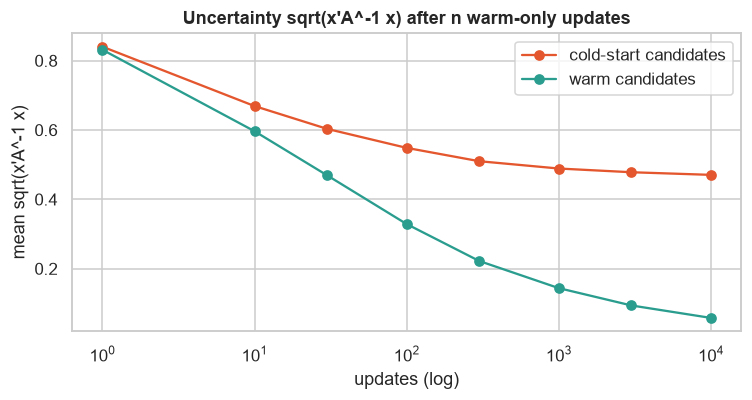

after 10,000 warm-only updates the cold/warm uncertainty ratio is 8.1x


In [9]:
grp = pack.groups.cpu().numpy(); cold_mask = pack.is_cold
warm_idx = np.where(~cold_mask)[0]
dev = pipe.dev
def mean_bonus(b, alpha=1.0):
    _, sd = b.predict(pack.ctx, pack.groups)
    sd = sd.cpu().numpy(); return sd[cold_mask].mean() * alpha, sd[~cold_mask].mean() * alpha

b = LinUCBBandit(pipe.ctx_dim, world.n_cats, dev, alpha=1.0, lam=cfg["bandit"]["lambda_reg"], hybrid=True,
                 shared_idx=[0, 1, 3, 4, 6, 8], refresh_every=200)
rng = np.random.default_rng(0)
checkpoints = [0, 10, 30, 100, 300, 1000, 3000, 10000]
curve, done = [], 0
for cp in checkpoints:
    while done < cp:                       # feed WARM contexts only (no cold item is ever shown)
        j = rng.choice(warm_idx)
        b.update(pack.ctx[j], int(grp[j]), 0.0); done += 1
    c, w_ = mean_bonus(b); curve.append((cp, c, w_))
curve = pd.DataFrame(curve, columns=["updates", "cold", "warm"])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curve.updates.replace(0, 1), curve.cold, "o-", color="#E4572E", label="cold-start candidates")
ax.plot(curve.updates.replace(0, 1), curve.warm, "o-", color="#2A9D8F", label="warm candidates")
ax.set(xscale="log", title="Uncertainty sqrt(x'A^-1 x) after n warm-only updates", xlabel="updates (log)", ylabel="mean sqrt(x'A^-1 x)"); ax.legend()
plt.tight_layout(); plt.show()
print("after 10,000 warm-only updates the cold/warm uncertainty ratio is %.1fx" % (curve.cold.iloc[-1] / curve.warm.iloc[-1]))

In [10]:
# The trained bandits (35,000 online updates each) on the real candidate pool of this user
for name in ["linucb_mmr", "linucb_high_expl"]:
    bb = pipe.bandits[name]; a = pipe.policies[name].alpha
    c, w_ = mean_bonus(bb, a)
    print(f"{name:18s} alpha={a:<4} mean bonus cold={c:.4f} warm={w_:.4f}  ({bb.n_updates:,} updates, max |A A^-1 - I| = {bb.max_inverse_error():.1e})")

linucb_mmr         alpha=0.35 mean bonus cold=0.0610 warm=0.0321  (35,000 updates, max |A A^-1 - I| = 5.5e-14)
linucb_high_expl   alpha=1.2  mean bonus cold=0.1560 warm=0.1079  (35,000 updates, max |A A^-1 - I| = 4.5e-14)


## 4. What do alpha and lambda cost? An exact, noise-free frontier

Instead of sampling clicks, score each slate by the **ground-truth expected reward** of its items (`env.expected_reward`), on 300 users with identical candidate pools.
This removes sampling noise, so differences are due to the policy alone. (Ground truth is used here only to evaluate; the policies never see it.)

In [11]:
rng = np.random.default_rng(1)
users = rng.choice(world.n_users, 300, replace=False)
packs = []
for u in users:
    pk = pipe.prepare(int(u), day=90); pipe.timer.commit()
    pk.true_r = env.expected_reward(np.full(len(pk.items), u), pk.items, pk.unseen_sub)
    packs.append(pk)
print("prepared", len(packs), "candidate pools; mean pool size", np.mean([len(p.items) for p in packs]).round(1))

mc = cfg["mmr"]; cap = cfg["guardrails"]["max_per_subcategory"]
def evaluate(alpha, lam, base_pol="linucb_mmr", use_bonus=True):
    pol = pipe.policies[base_pol]
    res = []
    for pk in packs:
        sc_ = pipe.score(pk, pol, alpha=alpha)["score"] if use_bonus else pk.u_rel
        picks, _, _ = mmr_select(sc_, pk.emb, pk.subcat_t, 5, lam, mc["w_embed_sim"], mc["w_subcat_sim"], cap)
        emb = pk.emb[torch.as_tensor(picks, device=pipe.dev)].cpu().numpy()
        res.append({"true_reward": pk.true_r[picks].mean(), "cold": pk.is_cold[picks].mean(), "discovery": (pk.tier[picks] >= 2).mean(),
                    "unseen_subcat": (pk.tier[picks] == 3).mean(), "ild": M.intra_list_diversity(emb), "p_click": pk.pc[picks].mean()})
    return pd.DataFrame(res).mean()

base = evaluate(0, 1.0, use_bonus=False)       # pure ranker: relevance-only utility, no MMR
print("pure ranker slate: true reward %.4f, cold share %.3f, discovery share %.3f, ILD %.3f" % (base.true_reward, base.cold, base.discovery, base.ild))
alphas = [0, 0.1, 0.35, 0.8, 1.5, 3.0]
a_sw = pd.DataFrame([evaluate(a, 0.75) for a in alphas]); a_sw.insert(0, "alpha", alphas)
display(a_sw.round(4))

prepared 300 candidate pools; mean pool size 59.6


pure ranker slate: true reward 0.0979, cold share 0.001, discovery share 0.284, ILD 0.935


,alpha,true_reward,cold,discovery,unseen_subcat,ild,p_click
0,0.00,0.0945,0.0007,0.4520,0.3607,0.9609,0.2048
1,0.10,0.0941,0.0013,0.4500,0.3593,0.9597,0.2049
2,0.35,0.0942,0.0093,0.4467,0.3487,0.9586,0.2046
3,0.80,0.0872,0.1853,0.4667,0.3433,0.9556,0.1886
4,1.50,0.0696,0.4620,0.5673,0.3667,0.9594,0.1518
5,3.00,0.0577,0.5900,0.6400,0.3907,0.9724,0.1236


,lambda,true_reward,cold,discovery,unseen_subcat,ild,p_click
0,1.00,0.0953,0.0093,0.4353,0.3307,0.9305,0.2058
1,0.90,0.0947,0.0087,0.4413,0.3360,0.9409,0.2056
2,0.75,0.0942,0.0093,0.4467,0.3487,0.9586,0.2046
3,0.60,0.0919,0.0093,0.4660,0.3693,0.9890,0.2008
4,0.40,0.0885,0.0093,0.4953,0.3920,1.0313,0.1938
5,0.20,0.0818,0.0173,0.5327,0.4287,1.0775,0.1790


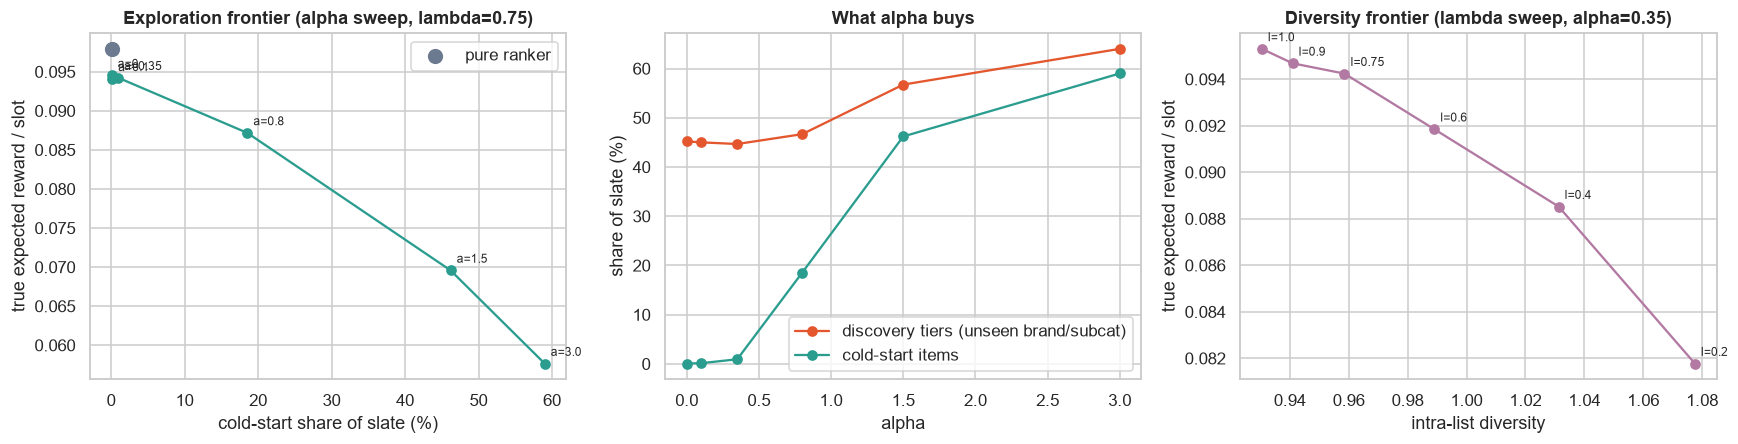

In [12]:
lams = [1.0, 0.9, 0.75, 0.6, 0.4, 0.2]
l_sw = pd.DataFrame([evaluate(0.35, l) for l in lams]); l_sw.insert(0, "lambda", lams)
display(l_sw.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(100 * a_sw.cold, a_sw.true_reward, "o-", color="#2A9D8F")
for a, x_, y_ in zip(alphas, 100 * a_sw.cold, a_sw.true_reward): ax[0].annotate(f"a={a}", (x_, y_), textcoords="offset points", xytext=(4, 5), fontsize=8)
ax[0].scatter([100 * base.cold], [base.true_reward], color="#6B7A8F", s=80, zorder=5, label="pure ranker"); ax[0].legend()
ax[0].set(title="Exploration frontier (alpha sweep, lambda=0.75)", xlabel="cold-start share of slate (%)", ylabel="true expected reward / slot")
ax[1].plot(a_sw.alpha, 100 * a_sw.discovery, "o-", color="#E4572E", label="discovery tiers (unseen brand/subcat)")
ax[1].plot(a_sw.alpha, 100 * a_sw.cold, "o-", color="#2A9D8F", label="cold-start items"); ax[1].legend()
ax[1].set(title="What alpha buys", xlabel="alpha", ylabel="share of slate (%)")
ax[2].plot(l_sw.ild, l_sw.true_reward, "o-", color="#B279A2")
for l, x_, y_ in zip(lams, l_sw.ild, l_sw.true_reward): ax[2].annotate(f"l={l}", (x_, y_), textcoords="offset points", xytext=(4, 5), fontsize=8)
ax[2].set(title="Diversity frontier (lambda sweep, alpha=0.35)", xlabel="intra-list diversity", ylabel="true expected reward / slot")
plt.tight_layout(); plt.show()

In [13]:
r0 = base.true_reward
for a in [0.35, 0.8, 1.5]:
    r = a_sw[a_sw.alpha == a].iloc[0]
    print(f"alpha={a:<4}: reward {100*(r.true_reward/r0-1):+.1f}% vs pure ranker, cold-start share {100*r.cold:.1f}% (pure ranker {100*base.cold:.2f}%)")

alpha=0.35: reward -3.8% vs pure ranker, cold-start share 0.9% (pure ranker 0.07%)
alpha=0.8 : reward -11.0% vs pure ranker, cold-start share 18.5% (pure ranker 0.07%)
alpha=1.5 : reward -29.0% vs pure ranker, cold-start share 46.2% (pure ranker 0.07%)


## 5. Do the guardrails throw away good items?

The price band drops most of the candidate pool (about 132 of 190 per request). We re-run candidate generation with the band disabled and compare the **true** reward of the items it removed
against the explored items it kept.

In [14]:
band = pipe.guard.band
rows = []
for u in users[:120]:
    pipe.guard.band = band;  kept = pipe.prepare(int(u), day=90); pipe.timer.commit()
    pipe.guard.band = 10.0;  full = pipe.prepare(int(u), day=90); pipe.timer.commit()
    pipe.guard.band = band
    dropped = ~np.isin(full.items, kept.items)
    tr = env.expected_reward(np.full(len(full.items), u), full.items, full.unseen_sub)
    explored = full.is_cold | (full.tier >= 2)
    rows.append({"user": u, "pool_with_band": len(kept.items), "pool_no_band": len(full.items),
                 "dropped_true_reward": tr[dropped].mean() if dropped.any() else np.nan,
                 "kept_explored_true_reward": tr[~dropped & explored].mean() if (~dropped & explored).any() else np.nan,
                 "kept_nonexplored_true_reward": tr[~explored].mean() if (~explored).any() else np.nan,
                 "dropped_cold": (dropped & full.is_cold).sum(), "total_cold": full.is_cold.sum()})
g = pd.DataFrame(rows)
print("pool size: %.0f with price band vs %.0f without" % (g.pool_with_band.mean(), g.pool_no_band.mean()))
print("true reward of items the band DROPPED: %.4f | explored items it KEPT: %.4f | non-explored items: %.4f" % (
    g.dropped_true_reward.mean(), g.kept_explored_true_reward.mean(), g.kept_nonexplored_true_reward.mean()))
print("share of cold-start candidates dropped by the band: %.0f%%" % (100 * g.dropped_cold.sum() / g.total_cold.sum()))

pool size: 59 with price band vs 190 without
true reward of items the band DROPPED: 0.0357 | explored items it KEPT: 0.0359 | non-explored items: 0.0559
share of cold-start candidates dropped by the band: 81%


Read the result: if the dropped items have about the same true reward as the explored items the band keeps, the band is removing discovery volume without removing bad items. It is the main tuning lever for discovery volume.

## 6. Comparing the four policies on discovery metrics

Results from the 3,000-request online simulation per policy (identical user sequence, 15,000 impressions each), computed from `sim_records_*.parquet`.

In [15]:
rec = pd.read_parquet(MET / "sim_records_all.parquet")
n_items, n_stock = world.n_items, int(world.items.in_stock.sum())
summ = pd.DataFrame({p: M.slate_metrics(rec[rec.policy == p], n_items, n_stock) for p in POL}).T
show = ["ctr", "avg_reward_per_impression", "realized_profit_per_slate", "repeat_purchase_rate_7d",
        "discovery_impression_share", "discovery_conversion_rate", "discovery_purchase_share",
        "cold_start_impression_share", "cold_start_conversion_rate", "serendipity_score",
        "catalog_coverage_pct", "gini_exposure", "shannon_entropy_normalised", "ild"]
tbl = summ[show].T; tbl.columns = [LAB[c] for c in tbl.columns]
display(tbl.astype(float).round(4))

,Pure ranker,Epsilon-greedy,LinUCB + MMR,High-explore LinUCB
ctr,0.1469,0.1362,0.1433,0.1424
avg_reward_per_impression,0.0885,0.0819,0.0855,0.0848
realized_profit_per_slate,0.3374,0.3074,0.3246,0.3149
repeat_purchase_rate_7d,0.2477,0.2390,0.2465,0.2282
discovery_impression_share,0.2821,0.3423,0.4508,0.4522
discovery_conversion_rate,0.0267,0.0220,0.0274,0.0231
discovery_purchase_share,0.1697,0.1837,0.2904,0.2488
cold_start_impression_share,0.0014,0.0132,0.0174,0.0630
cold_start_conversion_rate,0.0000,0.0152,0.0153,0.0180
serendipity_score,0.0003,0.0014,0.0063,0.0059


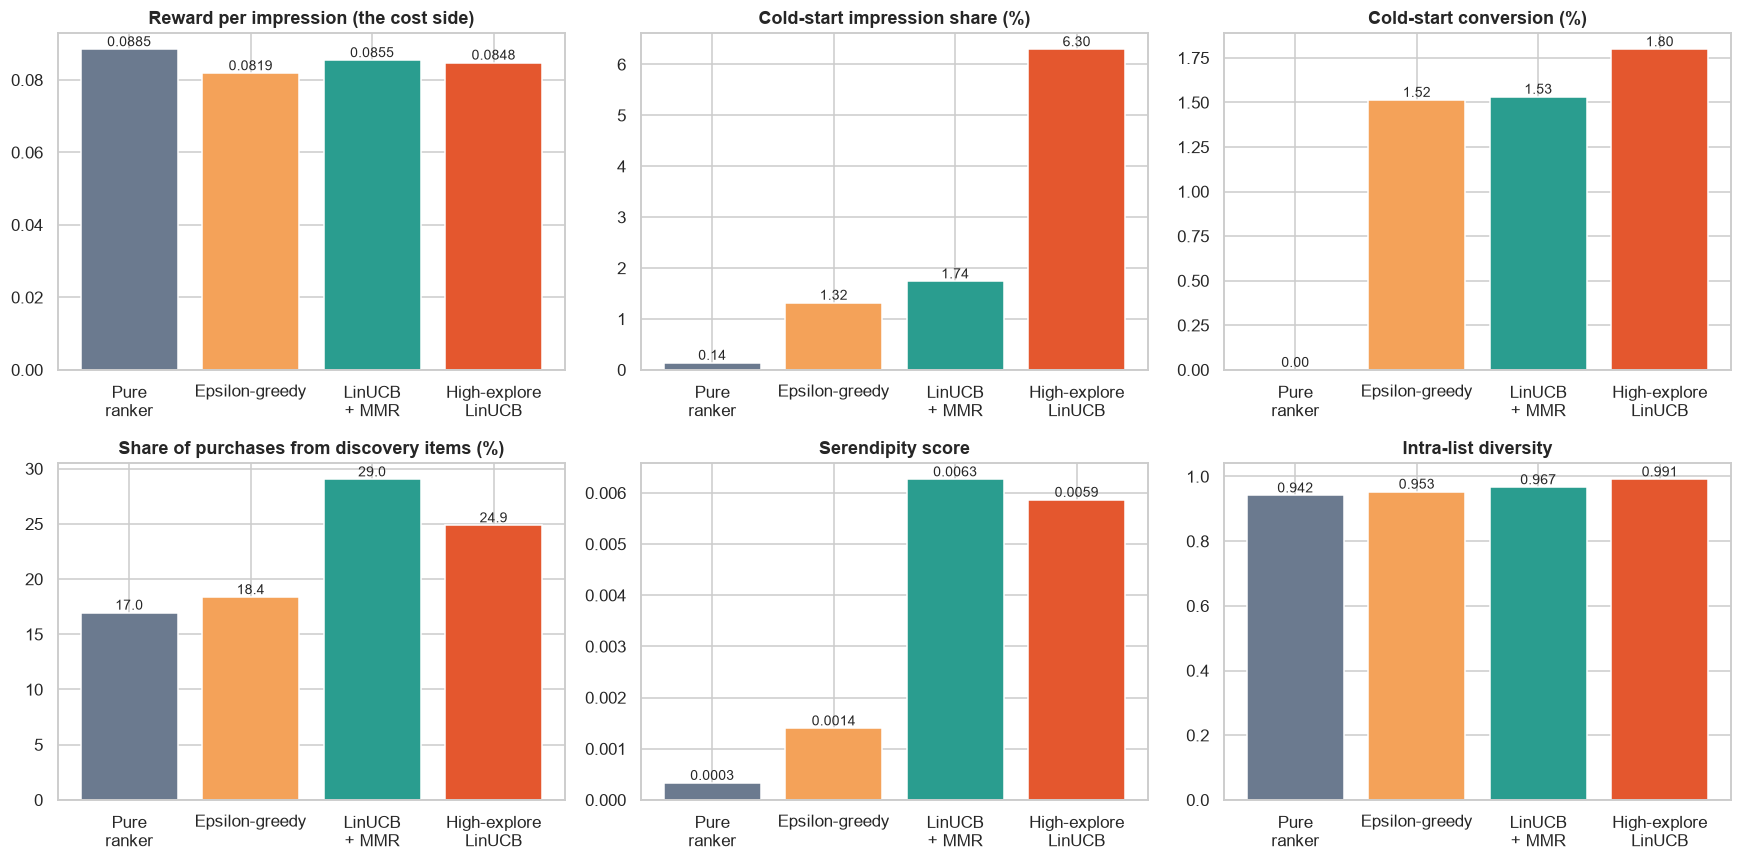

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
def bar(a, col, title, fmt="{:.3f}", scale=1.0):
    v = summ[col].values.astype(float) * scale
    a.bar(range(4), v, color=[COL[p] for p in POL]); a.set(title=title, xticks=range(4), xticklabels=[LAB[p].replace(" ", "\n", 1) for p in POL])
    for i, x_ in enumerate(v): a.text(i, x_, fmt.format(x_), ha="center", va="bottom", fontsize=9)
bar(ax[0, 0], "avg_reward_per_impression", "Reward per impression (the cost side)", "{:.4f}")
bar(ax[0, 1], "cold_start_impression_share", "Cold-start impression share (%)", "{:.2f}", 100)
bar(ax[0, 2], "cold_start_conversion_rate", "Cold-start conversion (%)", "{:.2f}", 100)
bar(ax[1, 0], "discovery_purchase_share", "Share of purchases from discovery items (%)", "{:.1f}", 100)
bar(ax[1, 1], "serendipity_score", "Serendipity score", "{:.4f}")
bar(ax[1, 2], "ild", "Intra-list diversity", "{:.3f}")
plt.tight_layout(); plt.show()

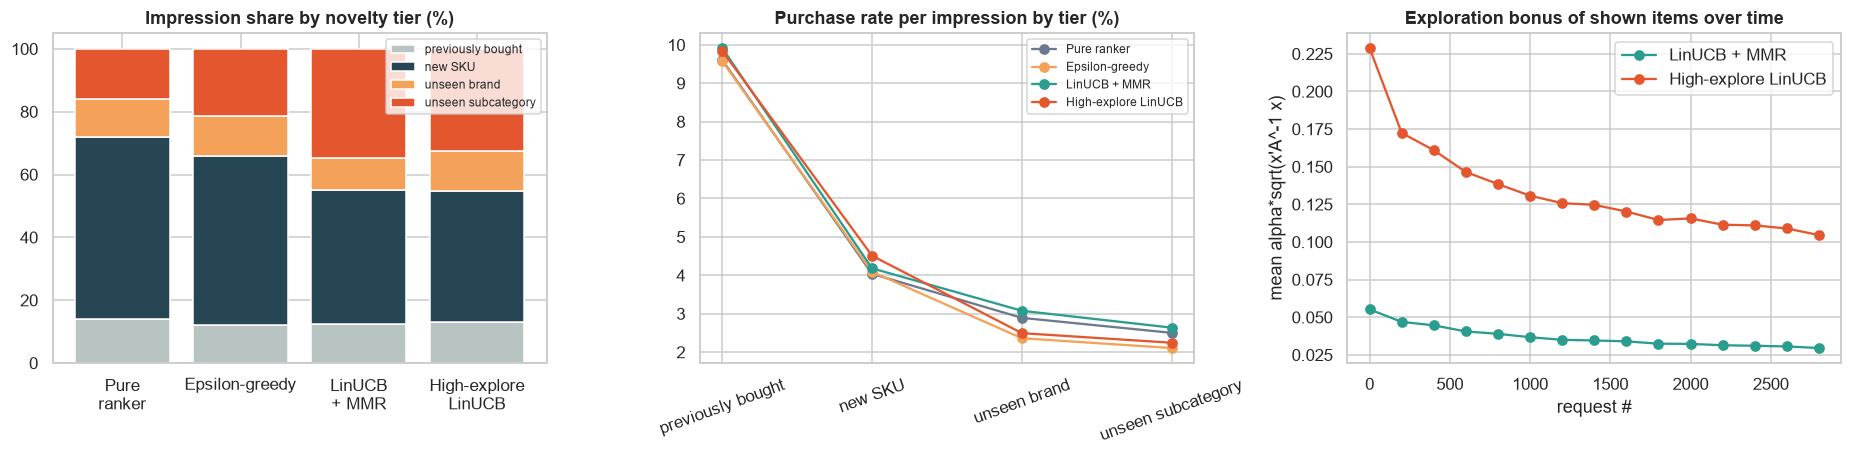

In [17]:
mix = rec.groupby(["policy", "tier"]).size().unstack(fill_value=0).reindex(POL); mix = mix.div(mix.sum(1), axis=0)
buy = rec.groupby(["policy", "tier"]).buy.mean().unstack().reindex(POL)
names = {0: "previously bought", 1: "new SKU", 2: "unseen brand", 3: "unseen subcategory"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
bottom = np.zeros(4)
for t, c in zip(range(4), ["#B8C4C2", "#264653", "#F4A259", "#E4572E"]):
    ax[0].bar(range(4), 100 * mix[t].values, bottom=bottom, color=c, label=names[t]); bottom += 100 * mix[t].values
ax[0].set(title="Impression share by novelty tier (%)", xticks=range(4), xticklabels=[LAB[p].replace(" ", "\n", 1) for p in POL]); ax[0].legend(fontsize=8)
for p in POL: ax[1].plot([names[t] for t in range(4)], 100 * buy.loc[p].values, "o-", color=COL[p], label=LAB[p])
ax[1].set(title="Purchase rate per impression by tier (%)"); ax[1].tick_params(axis="x", rotation=20); ax[1].legend(fontsize=8)
rec["bucket"] = rec.request // 200
for p in ["linucb_mmr", "linucb_high_expl"]:
    s_ = rec[rec.policy == p].groupby("bucket").exploration_bonus.mean(); ax[2].plot(s_.index * 200, s_.values, "o-", color=COL[p], label=LAB[p])
ax[2].set(title="Exploration bonus of shown items over time", xlabel="request #", ylabel="mean alpha*sqrt(x'A^-1 x)"); ax[2].legend()
plt.tight_layout(); plt.show()

In [18]:
r0 = summ.loc["pure_ranker"]
for p in POL[1:]:
    r = summ.loc[p]
    print(f"{LAB[p]:20s} reward {100*(r.avg_reward_per_impression/r0.avg_reward_per_impression-1):+5.1f}% | "
          f"cold-start share {100*r.cold_start_impression_share:5.2f}% (pure {100*r0.cold_start_impression_share:.2f}%) | "
          f"discovery purchase share {100*r.discovery_purchase_share:4.1f}% (pure {100*r0.discovery_purchase_share:.1f}%) | "
          f"serendipity x{r.serendipity_score/max(r0.serendipity_score,1e-9):.0f}")
print()
print("Concentration is still high: Gini of exposure =", summ.gini_exposure.astype(float).round(3).to_dict())

Epsilon-greedy       reward  -7.5% | cold-start share  1.32% (pure 0.14%) | discovery purchase share 18.4% (pure 17.0%) | serendipity x4
LinUCB + MMR         reward  -3.4% | cold-start share  1.74% (pure 0.14%) | discovery purchase share 29.0% (pure 17.0%) | serendipity x19
High-explore LinUCB  reward  -4.2% | cold-start share  6.30% (pure 0.14%) | discovery purchase share 24.9% (pure 17.0%) | serendipity x18

Concentration is still high: Gini of exposure = {'pure_ranker': 0.986, 'epsilon_greedy': 0.977, 'linucb_mmr': 0.987, 'linucb_high_expl': 0.983}


## 7. Online learning: one feedback event

`pipe.feedback()` is what `POST /feedback` calls. It performs a Sherman-Morrison rank-1 update of `A^-1` and `b` for the item's category group and refreshes the user's novelty/fatigue state.
We run it on a *copy* of the trained bandit so the notebook leaves the saved state untouched.

In [19]:
name = "linucb_mmr"
saved_bandit, saved_state = pipe.bandits[name], pipe.state
pipe.bandits[name] = _clone_bandit(saved_bandit); pipe.state = saved_state.clone()
try:
    out = pipe.recommend(UID, name, day=90)
    item = out["slate"][2]; j = out["_picks"][2]
    bonus_before = item["exploration_bonus"]
    x = out["_pack"].ctx[j:j+1]; g_ = out["_pack"].groups[j:j+1]
    mean_b, sd_b = pipe.bandits[name].predict(x, g_)
    n_b = pipe.bandits[name].n_updates
    for _ in range(25):   # the same kind of item gets clicked + bought 25 times
        res = pipe.feedback(UID, item["item_id"], reward=1.3, policy=name, day=90, clicked=True, purchased=True)
    mean_a, sd_a = pipe.bandits[name].predict(x, g_)
    print("feedback result:", res)
    print(f"bandit updates {n_b:,} -> {pipe.bandits[name].n_updates:,}")
    print(f"item {item['item_id']} (tier={item['novelty_tier']}, cold={item['is_cold_start']}): sqrt(x'A^-1 x) {sd_b.item():.5f} -> {sd_a.item():.5f}  (bonus x alpha {pipe.policies[name].alpha}: {bonus_before:.4f} -> {pipe.policies[name].alpha*sd_a.item():.4f})")
    print("max |A A^-1 - I| after the updates: %.1e" % pipe.bandits[name].max_inverse_error())
finally:
    pipe.bandits[name], pipe.state = saved_bandit, saved_state

feedback result: {'updated': True, 'policy': 'linucb_mmr', 'recomputed_context': False, 'bandit_updates': 35025}
bandit updates 35,000 -> 35,025
item 8823 (tier=previously_bought, cold=False): sqrt(x'A^-1 x) 0.07246 -> 0.06813  (bonus x alpha 0.35: 0.0254 -> 0.0238)
max |A A^-1 - I| after the updates: 5.4e-13


## 8. Evaluating discovery policies offline (IPS, SNIPS, DR, Switch-DR)

Every displayed item carries its Boltzmann propensity, so a log collected under one stochastic policy can score the others. The OPE log was collected with a softened pure-ranker behaviour policy (tau=0.10);
each policy is evaluated as its Boltzmann variant. Because the simulator exposes the ground truth we can check the estimators.

estimator,ground truth,DM,IPS,SNIPS,DR,Switch-DR
policy,,,,,,
pure_ranker,0.0854,0.1149,0.0868,0.0865,0.0865,0.0865
epsilon_greedy,0.0774,0.1045,0.0783,0.0780,0.0778,0.0778
linucb_mmr,0.0798,0.1099,0.0809,0.0806,0.0807,0.0807
linucb_high_expl,0.0692,0.0971,0.0698,0.0697,0.0699,0.0699


relative error vs ground truth (%):


estimator,DM,IPS,SNIPS,DR,Switch-DR
policy,,,,,
pure_ranker,34.43,1.62,1.19,1.20,1.20
epsilon_greedy,35.05,1.18,0.84,0.56,0.56
linucb_mmr,37.65,1.36,0.95,1.08,1.08
linucb_high_expl,40.36,0.89,0.74,0.97,0.97


effective sample size fraction: {'Pure ranker': 0.74, 'Epsilon-greedy': 0.85, 'LinUCB + MMR': 0.79, 'High-explore LinUCB': 0.9} | max weight: 6.4


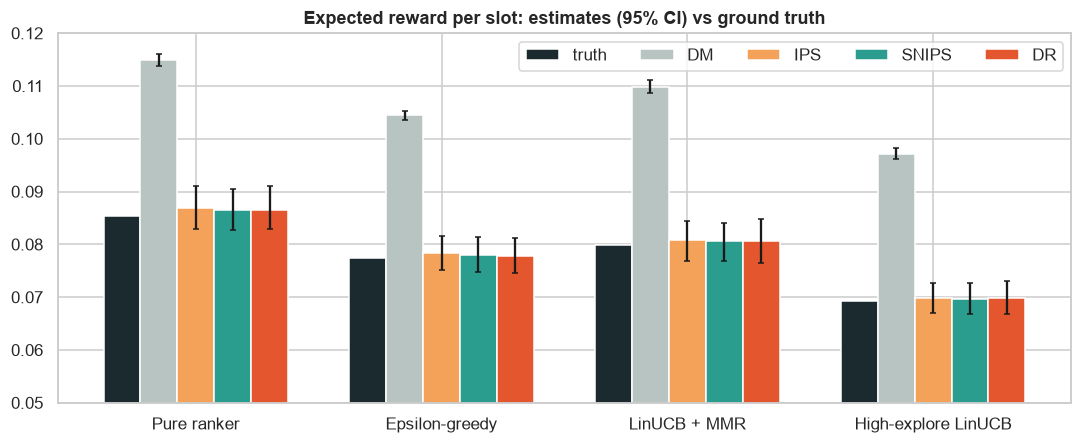

In [20]:
ope = pd.read_parquet(MET / "ope_log.parquet")
cfg_ope = dict(cfg); cfg_ope["ope"] = dict(cfg["ope"], n_bootstrap=300)
res = run_ope(ope, POL, cfg_ope)
tab = ope_table(res)
cols = ["DM", "IPS", "SNIPS", "DR", "Switch-DR"]
piv = tab.pivot(index="policy", columns="estimator", values="estimate").reindex(POL)[cols]
piv.insert(0, "ground truth", [res[p]["DM"]["true_value"] for p in POL])
display(piv.round(4))
err = tab.pivot(index="policy", columns="estimator", values="rel_error_pct").reindex(POL)[cols]
print("relative error vs ground truth (%):"); display(err.round(2))
print("effective sample size fraction:", {LAB[p]: round(res[p]["diagnostics"]["ess_fraction"], 2) for p in POL}, "| max weight:", round(max(res[p]["diagnostics"]["max_weight"] for p in POL), 1))

fig, ax = plt.subplots(figsize=(10, 4.2))
ests = ["DM", "IPS", "SNIPS", "DR"]; w = 0.15
for k, e in enumerate(["truth"] + ests):
    vals = [res[p]["DM"]["true_value"] if e == "truth" else res[p][e]["estimate"] for p in POL]
    errs = None if e == "truth" else [[res[p][e]["estimate"] - res[p][e]["ci_low"] for p in POL], [res[p][e]["ci_high"] - res[p][e]["estimate"] for p in POL]]
    ax.bar(np.arange(4) + (k - 2) * w, vals, w, yerr=errs, capsize=2, label=e, color=["#1B2A2F", "#B8C4C2", "#F4A259", "#2A9D8F", "#E4572E"][k])
ax.set(title="Expected reward per slot: estimates (95% CI) vs ground truth", xticks=range(4), xticklabels=[LAB[p] for p in POL], ylim=(0.05, 0.12)); ax.legend(ncol=5)
plt.tight_layout(); plt.show()

## Takeaways

* A relevance ranker scores new SKUs ~38% lower at equal relevance; the discovery engine is what puts them back in front of users.
* The **LinUCB bonus is directed exploration**: warm contexts' uncertainty collapses with data while the cold-start direction keeps a higher bonus (section 3).
* **alpha** moves cold-start share along a steep frontier (section 4, exact ground-truth reward on 300 users): alpha=0.35 costs about 4% reward for roughly a 10x cold-start share, alpha=0.8 costs about 11% for ~18% cold-start slots, alpha=1.5 costs about 29%. **lambda** trades relevance for diversity at a lower price (lambda=0.75: about -1% reward for +0.03 ILD).
* The **price-band guardrail** removes about 70% of the candidate pool (59 of 190 survive) and about 80% of cold-start candidates; the items it drops are no better or worse in true reward than the explored items it keeps (0.0357 vs 0.0359), so it is the main lever on discovery volume and worth tuning (section 5).
* Judge discovery on its own metrics (cold-start share and conversion, discovery purchase share, serendipity, breadth, ILD) *and* on the reward it costs (section 6).
* Propensities make discovery policies **evaluable offline**; IPS/SNIPS/DR track the truth while the direct method is biased (section 8).

Known limits: synthetic data, a modest ranker (AUC 0.63), exposure that is still highly concentrated (Gini ~0.98), and OPE that evaluates stochastic Boltzmann variants of the deployed (greedy-MMR) policies.